<a href="https://colab.research.google.com/github/rdvergara-feua/Vergara-Raynard-CS0065-AN43/blob/main/TA3_VERGARA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
#Step 1
%pip install pandas numpy matplotlib

In [2]:
#Step 2
import math
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

In [3]:
#Step 3
rows = [
    ("C01", "Flood", 3, 5000, "Urban", 2, 4, 6, 2500, "Evacuate low-lying areas, deploy boats", 4.5),
    ("C02", "Flood", 4, 12000, "Rural", 4, 8, 14, 7000, "Boat rescue, airlift isolated villages", 4.0),
    ("C03", "Flood", 2, 2000, "Coastal", 2, 2, 3, 900, "Pre-emptive evacuation, sandbagging", 4.8),
    ("C04", "Typhoon", 4, 20000, "Coastal", 3, 10, 24, 12000, "Mass evacuation, pre-position relief goods", 4.2),
    ("C05", "Typhoon", 3, 8000, "Urban", 2, 6, 10, 4000, "Shelter in place, clear drainage, standby rescue", 4.6),
    ("C06", "Typhoon", 5, 30000, "Coastal", 4, 15, 36, 20000, "Forced evacuation, military support, field hospital", 3.9),
    ("C07", "Earthquake", 4, 15000, "Urban", 3, 12, 18, 9000, "Search and rescue, structural inspection, medical triage", 4.1),
    ("C08", "Earthquake", 3, 6000, "Rural", 4, 6, 8, 3500, "Road clearing, medical teams, temporary shelters", 4.3),
    ("C09", "Earthquake", 5, 40000, "Urban", 4, 20, 48, 26000, "Urban SAR, field hospitals, international aid", 3.7),
    ("C10", "Fire", 3, 3000, "Urban", 1, 5, 4, 1500, "Fire containment, evacuate buildings, medical standby", 4.7),
    ("C11", "Fire", 4, 1500, "Rural", 4, 4, 3, 1000, "Firebreaks, air water drops, evacuate villages", 4.0),
    ("C12", "Landslide", 4, 2500, "Rural", 5, 6, 5, 1800, "Rescue teams, evacuate slopes, road clearing", 3.8),
    ("C13", "Landslide", 3, 1200, "Rural", 4, 3, 3, 800, "Evacuate risk zones, monitor slopes", 4.5),
    ("C14", "Volcanic Eruption", 4, 18000, "Rural", 3, 9, 20, 11000, "Evacuate danger radius, distribute masks, set up shelters", 4.2),
    ("C15", "Flood", 5, 25000, "Urban", 3, 14, 30, 16000, "Mass evacuation, rescue boats, field hospitals", 3.9),
]
cols = ["case_id", "disaster_type", "severity", "population", "area_type", "access_difficulty",
        "teams", "evac_centers", "relief_packs", "action", "outcome"]
pd.DataFrame(rows, columns=cols).to_csv("case_base.csv", index=False)

#upload = files.upload()
case_base = pd.read_csv("case_base.csv")
print(case_base.shape)
case_base.head()

(15, 11)


,case_id,disaster_type,severity,population,area_type,access_difficulty,teams,evac_centers,relief_packs,action,outcome
0,C01,Flood,3,5000,Urban,2,4,6,2500,"Evacuate low-lying areas, deploy boats",4.5
1,C02,Flood,4,12000,Rural,4,8,14,7000,"Boat rescue, airlift isolated villages",4.0
2,C03,Flood,2,2000,Coastal,2,2,3,900,"Pre-emptive evacuation, sandbagging",4.8
3,C04,Typhoon,4,20000,Coastal,3,10,24,12000,"Mass evacuation, pre-position relief goods",4.2
4,C05,Typhoon,3,8000,Urban,2,6,10,4000,"Shelter in place, clear drainage, standby rescue",4.6


In [4]:
#Step 4
PROBLEM = ["disaster_type", "severity", "population", "area_type", "access_difficulty"]
SOLUTION = ["teams", "evac_centers", "relief_packs", "action"]

print("Problem features :", PROBLEM)
print("Solution features:", SOLUTION)
print("Outcome (quality): outcome (1-5)")
case_base[["case_id"] + PROBLEM + SOLUTION + ["outcome"]].head(3)

Problem features : ['disaster_type', 'severity', 'population', 'area_type', 'access_difficulty']
Solution features: ['teams', 'evac_centers', 'relief_packs', 'action']
Outcome (quality): outcome (1-5)


,case_id,disaster_type,severity,population,area_type,access_difficulty,teams,evac_centers,relief_packs,action,outcome
0,C01,Flood,3,5000,Urban,2,4,6,2500,"Evacuate low-lying areas, deploy boats",4.5
1,C02,Flood,4,12000,Rural,4,8,14,7000,"Boat rescue, airlift isolated villages",4.0
2,C03,Flood,2,2000,Coastal,2,2,3,900,"Pre-emptive evacuation, sandbagging",4.8


In [5]:
#Step 5
WEIGHTS = {"disaster_type": 0.30, "severity": 0.25, "population": 0.20,
           "area_type": 0.15, "access_difficulty": 0.10}
MIN_SIM = 0.75


def local_sim(f, a, b):
    if f in ("disaster_type", "area_type"):
        return 1.0 if a == b else 0.0
    if f == "population":
        return min(a, b) / max(a, b)
    return 1 - abs(a - b) / 4


def global_sim(query, case):
    return sum(WEIGHTS[f] * local_sim(f, query[f], case[f]) for f in WEIGHTS)

In [6]:
#Step 6
def retrieve(query, cb, k=3):
    sims = cb.apply(lambda r: global_sim(query, r), axis=1)
    top = cb.assign(similarity=sims.round(3)).sort_values("similarity", ascending=False).head(k)
    return top.reset_index(drop=True)

In [7]:
#Step 7
def adapt(query, case):
    pop_r = query["population"] / case["population"]
    sev_r = query["severity"] / case["severity"]
    notes = []

    sol = {
        "teams": math.ceil(case["teams"] * math.sqrt(pop_r) * sev_r),
        "evac_centers": math.ceil(case["evac_centers"] * pop_r),
        "relief_packs": round(case["relief_packs"] * pop_r),
        "action": case["action"],
    }
    notes.append(f"Resources scaled by population x{pop_r:.2f} and severity x{sev_r:.2f}")

    if query["disaster_type"] != case["disaster_type"]:
        notes.append(f"Case is a {case['disaster_type']} case, review action for {query['disaster_type']}")
    if query["access_difficulty"] >= 4 and case["access_difficulty"] < 4:
        sol["action"] += ", add air/boat access"
        notes.append("Hard access: added air/boat access")
    if query["severity"] > case["severity"]:
        sol["action"] += ", raise alert level"
        notes.append("Higher severity: alert level raised")
    return sol, notes

In [8]:
#Step 8
def retain(query, sol, outcome, cb, best_sim):
    if best_sim >= 0.98:
        print("Case already stored, not added.")
        return cb
    new_id = f"C{len(cb) + 1:02d}"
    new = {"case_id": new_id, **query, **sol, "outcome": outcome}
    print("Retained as", new_id)
    return pd.concat([cb, pd.DataFrame([new])], ignore_index=True)


def validate(q):
    errs = []
    if not str(q.get("disaster_type", "")).strip():
        errs.append("Disaster type required")
    if q.get("area_type") not in ("Urban", "Rural", "Coastal"):
        errs.append("Area must be Urban, Rural, or Coastal")
    if not 1 <= q.get("severity", 0) <= 5:
        errs.append("Severity must be 1-5")
    if not 1 <= q.get("access_difficulty", 0) <= 5:
        errs.append("Access difficulty must be 1-5")
    if q.get("population", 0) <= 0:
        errs.append("Population must be above 0")
    return errs


def solve(q, cb):
    errs = validate(q)
    if errs:
        return None, None, None, errs
    top = retrieve(q, cb)
    best = top.iloc[0]
    if best.similarity < MIN_SIM:
        return top, None, None, ["No similar case found. Manual planning needed."]
    sol, notes = adapt(q, best)
    return top, sol, notes, []

In [9]:
#Step 9
new_problem = {"disaster_type": "Typhoon", "severity": 4, "population": 15000,
               "area_type": "Urban", "access_difficulty": 3}

top, sol, notes, errs = solve(new_problem, case_base)
print("NEW PROBLEM:", new_problem)
print("\nRETRIEVED CASES")
display(top[["case_id", "disaster_type", "severity", "population", "area_type", "similarity", "outcome"]])

print("ADAPTED SOLUTION (based on", top.iloc[0].case_id + ")")
print(sol)
print("\nWhy:")
for n in notes:
    print("-", n)

NEW PROBLEM: {'disaster_type': 'Typhoon', 'severity': 4, 'population': 15000, 'area_type': 'Urban', 'access_difficulty': 3}

RETRIEVED CASES


,case_id,disaster_type,severity,population,area_type,similarity,outcome
0,C05,Typhoon,3,8000,Urban,0.819,4.6
1,C04,Typhoon,4,20000,Coastal,0.800,4.2
2,C07,Earthquake,4,15000,Urban,0.700,4.1


ADAPTED SOLUTION (based on C05)
{'teams': 11, 'evac_centers': 19, 'relief_packs': 7500, 'action': 'Shelter in place, clear drainage, standby rescue, raise alert level'}

Why:
- Resources scaled by population x1.88 and severity x1.33
- Higher severity: alert level raised


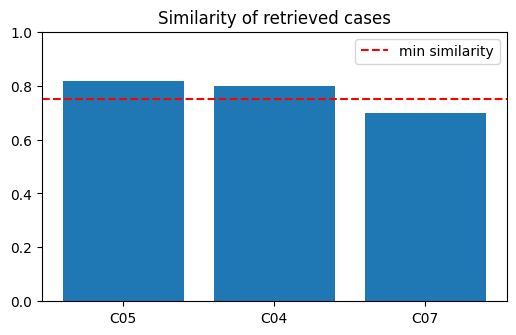

In [10]:
#Step 10
plt.figure(figsize=(6, 3.5))
plt.bar(top.case_id, top.similarity, color="tab:blue")
plt.axhline(MIN_SIM, color="red", ls="--", label="min similarity")
plt.ylim(0, 1)
plt.title("Similarity of retrieved cases")
plt.legend()
plt.show()

In [11]:
#Step 11
print("Case base before:", len(case_base))
case_base = retain(new_problem, sol, outcome=4.4, cb=case_base, best_sim=top.iloc[0].similarity)
print("Case base after :", len(case_base))
case_base.tail(2)

Case base before: 15
Retained as C16
Case base after : 16


,case_id,disaster_type,severity,population,area_type,access_difficulty,teams,evac_centers,relief_packs,action,outcome
14,C15,Flood,5,25000,Urban,3,14,30,16000,"Mass evacuation, rescue boats, field hospitals",3.9
15,C16,Typhoon,4,15000,Urban,3,11,19,7500,"Shelter in place, clear drainage, standby resc...",4.4


In [12]:
#Step 12
similar_problem = {**new_problem, "population": 16000}
top2, sol2, notes2, errs2 = solve(similar_problem, case_base)
display(top2[["case_id", "disaster_type", "severity", "population", "similarity"]])
print("Best match is now the retained case:", top2.iloc[0].case_id)
print(sol2)

,case_id,disaster_type,severity,population,similarity
0,C16,Typhoon,4,15000,0.988
1,C05,Typhoon,3,8000,0.812
2,C04,Typhoon,4,20000,0.810


Best match is now the retained case: C16
{'teams': 12, 'evac_centers': 21, 'relief_packs': 8000, 'action': 'Shelter in place, clear drainage, standby rescue, raise alert level'}


In [13]:
#Step 13
tests = [
    ("Normal", {"disaster_type": "Flood", "severity": 3, "population": 6000, "area_type": "Urban", "access_difficulty": 2}),
    ("Exact copy", {"disaster_type": "Fire", "severity": 3, "population": 3000, "area_type": "Urban", "access_difficulty": 1}),
    ("Boundary severity 5", {"disaster_type": "Earthquake", "severity": 5, "population": 35000, "area_type": "Urban", "access_difficulty": 4}),
    ("Hard access", {"disaster_type": "Landslide", "severity": 4, "population": 2000, "area_type": "Rural", "access_difficulty": 5}),
    ("Unknown type", {"disaster_type": "Tsunami", "severity": 4, "population": 10000, "area_type": "Coastal", "access_difficulty": 3}),
    ("Invalid severity", {"disaster_type": "Flood", "severity": 9, "population": 5000, "area_type": "Urban", "access_difficulty": 2}),
    ("Missing type", {"disaster_type": "", "severity": 3, "population": 5000, "area_type": "Urban", "access_difficulty": 2}),
]

out = []
for name, q in tests:
    t, s, n, e = solve(q, case_base)
    if e and t is None:
        out.append([name, "-", None, "Rejected: " + e[0]])
    elif e:
        out.append([name, t.iloc[0].case_id, t.iloc[0].similarity, e[0]])
    else:
        out.append([name, t.iloc[0].case_id, t.iloc[0].similarity,
                    f"{s['teams']} teams, {s['evac_centers']} centers, {s['relief_packs']} packs"])

pd.DataFrame(out, columns=["test", "best_case", "similarity", "result"])

,test,best_case,similarity,result
0,Normal,C01,0.967,"5 teams, 8 centers, 3000 packs"
1,Exact copy,C10,1.000,"5 teams, 4 centers, 1500 packs"
2,Boundary severity 5,C09,0.975,"19 teams, 42 centers, 22750 packs"
3,Hard access,C12,0.960,"6 teams, 4 centers, 1440 packs"
4,Unknown type,C04,0.600,No similar case found. Manual planning needed.
5,Invalid severity,-,NaN,Rejected: Severity must be 1-5
6,Missing type,-,NaN,Rejected: Disaster type required


In [14]:
#Step 14
def ask(label, cast=str, valid=None):
    while True:
        try:
            v = cast(input(label + ": ").strip())
            if valid is None or valid(v):
                return v
        except ValueError:
            pass
        print("Invalid, try again.")


my_problem = {
    "disaster_type": ask("Disaster type (Flood/Typhoon/Earthquake/Fire/Landslide)", valid=lambda v: v != "").title(),
    "severity": ask("Severity 1-5", int, lambda v: 1 <= v <= 5),
    "population": ask("Population affected", int, lambda v: v > 0),
    "area_type": ask("Area (Urban/Rural/Coastal)", valid=lambda v: v.title() in ("Urban", "Rural", "Coastal")).title(),
    "access_difficulty": ask("Access difficulty 1-5", int, lambda v: 1 <= v <= 5),
}

t, s, n, e = solve(my_problem, case_base)
if e:
    print(e[0])
else:
    print("Recommended response (based on", t.iloc[0].case_id + "):")
    print(s)
    for x in n:
        print("-", x)

Disaster type (Flood/Typhoon/Earthquake/Fire/Landslide): Flood
Severity 1-5: 4
Population affected: 2000
Area (Urban/Rural/Coastal): Urban
Access difficulty 1-5: 3
Recommended response (based on C01):
{'teams': 4, 'evac_centers': 3, 'relief_packs': 1000, 'action': 'Evacuate low-lying areas, deploy boats, raise alert level'}
- Resources scaled by population x0.40 and severity x1.33
- Higher severity: alert level raised


In [15]:
#Step 15
case_base.to_csv("case_base_updated.csv", index=False)
files.download("case_base_updated.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>